# 03 · 下游任务结果可视化

读取 `phenostate-retrieval` 的一个正式结果目录，不训练模型、不提取 embedding、不重新计算任务。
同一次评价保证各模型共用划分、有效孔位和候选资格。先在 val 固定方案，再查看 test。
公开预训练参考与本地训练模型的上游数据/计算预算不同，不能解释为同预算架构消融。

In [3]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    "/NFS2_home/NFS2_home_3/xkj2006/cell_painting/project/PhenoState"
)

RESULT_DIR = Path(
    "/NFS2_home/NFS2_home_3/xkj2006/cell_painting/project/PhenoState/results/downstream_val_all"
)

PUBLIC_MODELS = {'OpenPhenom', 'MAE-L-8', 'MAE-G-8'}
TASKS = ('activity', 'same-guide', 'compound', 'cross-guide')
PRIMARY = {task: 'mrr' if task == 'cross-guide' else 'map' for task in TASKS}
if not (RESULT_DIR / 'protocol.json').is_file():
    raise FileNotFoundError(f'未找到正式评价结果：{RESULT_DIR}。先运行 phenostate-retrieval，或设置 PHENOSTATE_RESULTS_DIR。')
protocol = json.loads((RESULT_DIR / 'protocol.json').read_text(encoding='utf-8'))
coverage = json.loads((RESULT_DIR / 'coverage.json').read_text(encoding='utf-8'))
summary = pd.read_csv(RESULT_DIR / 'summary.csv')
models = summary.model.drop_duplicates().tolist()
results = {}
for model in models:
    for task in TASKS:
        path = RESULT_DIR / model / task / 'metrics.json'
        if path.is_file():
            results[model, task] = json.loads(path.read_text(encoding='utf-8'))

## 1. 协议、来源和覆盖率

先核对 train gallery、query split、预处理、相似度和各任务可评价率。
embedding 覆盖率与任务覆盖率的分母不同；缺失/不可评价记为 NA，不用 0 代替。
整板划分只规定当前评价孔位，不能撤销公开模型已经接触过 RxRx3 的预训练历史。

In [4]:
display(pd.Series({key: protocol.get(key) for key in ('query_split', 'gallery_split', 'tasks', 'metric',
        'preprocessing', 'seed', 'n_bootstrap', 'n_permutations', 'n_null', 'split_scope')}, name='value').to_frame())
display(pd.Series({key: value for key, value in coverage.items()
                   if isinstance(value, (int, float))}, name='value').to_frame())
display(pd.DataFrame([{'model': name, 'public_reference': name in PUBLIC_MODELS,
        'dimension': info.get('embedding_dimension'), 'source_kind': info.get('source_kind'),
        'provenance': info.get('checkpoint_verification')}
        for name, info in protocol['models'].items()]))
columns = [c for c in ('model', 'task', 'score', 'n_evaluable_queries', 'n_groups', 'overall_query_coverage',
           'overall_group_coverage', 'replication_coverage', 'excluded_reasons') if c in summary]
display(summary[columns])

def points(ax, records, metric, bounds=(0, 1), random_field=None):
    for position, (label, stats) in enumerate(records):
        score = stats.get(metric)
        if score is None or not np.isfinite(score):
            ax.text(0.02, position, 'NA', va='center')
            continue
        interval = stats.get('ci95', {}).get(metric)
        if interval is not None and np.isfinite(interval).all():
            ax.hlines(position, interval[0], interval[1], color='tab:blue', linewidth=2)
        ax.scatter(score, position, marker='^' if label.split(' / ')[0] in PUBLIC_MODELS else 'o', color='tab:blue', clip_on=False)
        if random_field and stats.get(random_field) is not None:
            ax.scatter(stats[random_field], position, marker='x', color='gray')
    ax.set_yticks(range(len(records)), [label for label, _ in records])
    ax.set_ylim(-0.5, max(len(records) - 0.5, 0.5))
    if bounds is not None:
        ax.set_xlim(*bounds)
    ax.invert_yaxis()
    ax.set_xlabel(metric)
    ax.grid(axis='x', alpha=0.25)
    if not records:
        ax.text(0.5, 0.5, 'Not evaluated', transform=ax.transAxes, ha='center')

,value
query_split,val
gallery_split,train
tasks,"[activity, same-guide, compound, cross-guide]"
metric,cosine
preprocessing,raw
seed,2026
n_bootstrap,1000
n_permutations,1000
n_null,500
split_scope,evaluation wells only; upstream pretraining ov...


,value
n_metadata,222601.0
n_requested,198654.0
n_common_before_finite,198654.0
n_common,198654.0
coverage,1.0
n_requested_query_wells,24718.0
n_requested_gallery_wells,173936.0
n_common_valid_query_wells,24718.0
n_common_valid_gallery_wells,173936.0
query_embedding_coverage,1.0


,model,public_reference,dimension,source_kind,provenance
0,mae,False,512,split exports,unverified; arbitrary embedding source
1,ca_mae,False,512,split exports,unverified; arbitrary embedding source
2,diffmae,False,512,split exports,unverified; arbitrary embedding source
3,cnn_mae,False,512,split exports,unverified; arbitrary embedding source


,model,task,score,n_evaluable_queries,n_groups,overall_query_coverage,overall_group_coverage,replication_coverage,excluded_reasons
0,mae,activity,0.350061,14621,9257,0.994897,0.999137,NaN,"{""no_strictly_matched_controls"": 75}"
1,mae,same-guide,0.075645,8500,733,0.998590,0.998638,0.613252,"{""no_negative_candidates"": 12}"
2,mae,compound,0.018611,6180,4853,0.999353,0.999176,0.999178,"{""no_negative_candidates"": 4}"
3,mae,cross-guide,0.384094,8410,718,0.988017,0.978202,NaN,"{""no_cross_experiment_positives"": 90, ""no_nega..."
4,ca_mae,activity,0.345273,14621,9257,0.994897,0.999137,NaN,"{""no_strictly_matched_controls"": 75}"
5,ca_mae,same-guide,0.071788,8500,733,0.998590,0.998638,0.613252,"{""no_negative_candidates"": 12}"
6,ca_mae,compound,0.017882,6180,4853,0.999353,0.999176,0.999178,"{""no_negative_candidates"": 4}"
7,ca_mae,cross-guide,0.380385,8410,718,0.988017,0.978202,NaN,"{""no_cross_experiment_positives"": 90, ""no_nega..."
8,diffmae,activity,0.360766,14621,9257,0.994897,0.999137,NaN,"{""no_strictly_matched_controls"": 75}"
9,diffmae,same-guide,0.068611,8500,733,0.998590,0.998638,0.613252,"{""no_negative_candidates"": 12}"


## 2. 主指标与组级 95% CI

activity、same-guide、compound 看 mAP，cross-guide 看 MRR。四个面板分别解释，不合成为一个总分。
三角点为配置中的公开参考，圆点为其他模型；灰色叉为协议提供的随机基线。
CI 直接读取扰动组 bootstrap；它不是训练随机种子的不确定性。

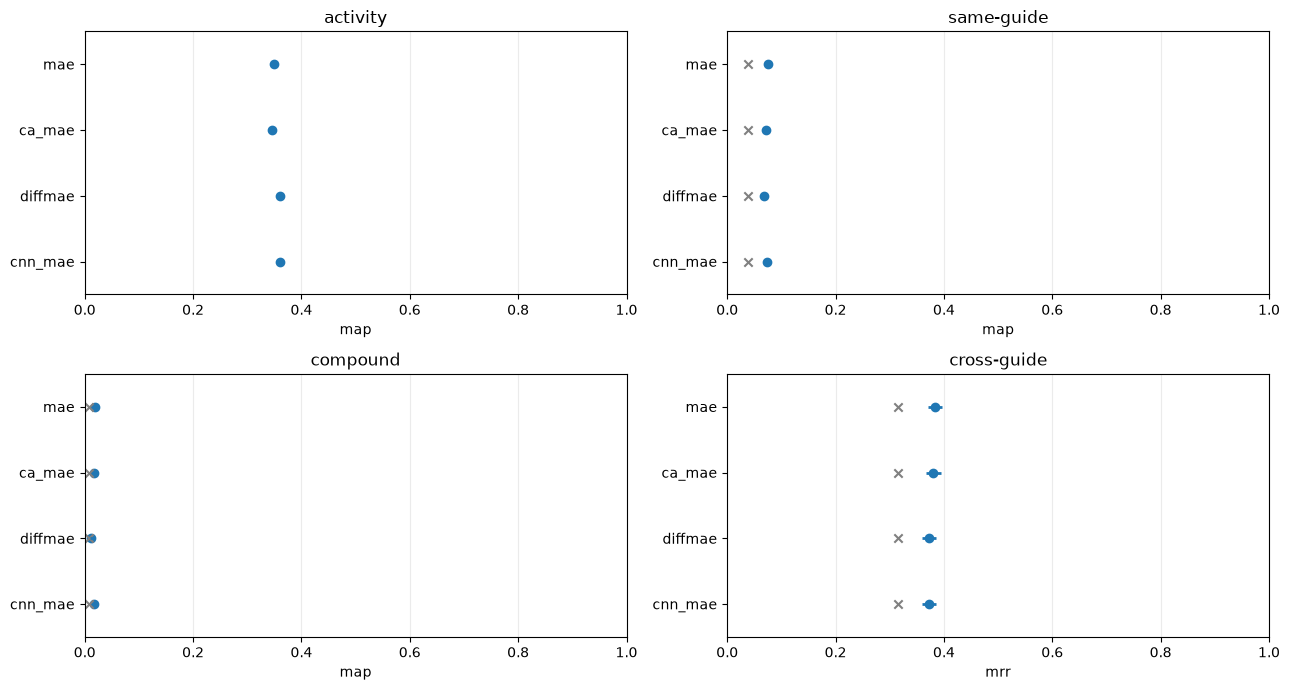

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, max(7, len(models) * 0.8)), squeeze=False)
for ax, task in zip(axes.flat, TASKS):
    records = [(name, results[name, task]['summary']) for name in models if (name, task) in results]
    points(ax, records, PRIMARY[task], random_field='random_mrr' if task == 'cross-guide' else 'random_ap')
    ax.set_title(task)
plt.tight_layout()
plt.show()

## 3. Recall@K、重复一致性与显著活性

Recall 是找回全部正例的比例，不是 Hit@K。percent replicating、percent active 已按 0–100 存储，不再乘 100。
显著活性按 CRISPR/COMPOUND 分开，受严格对照匹配、重复数、置换次数及 BH 阈值影响。
energy distance 另看诊断表，不能与 mAP/MRR 放在同一评分轴上。

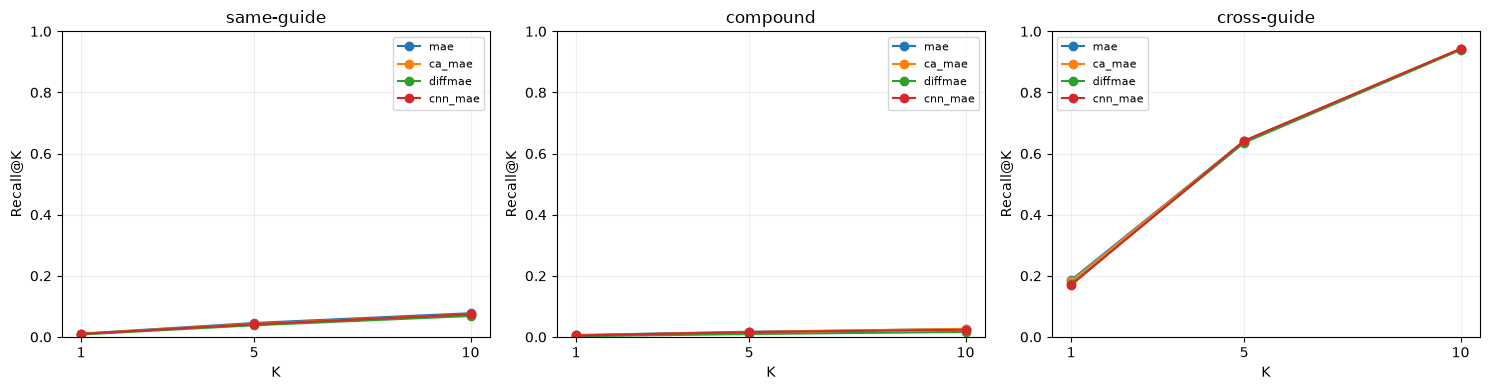

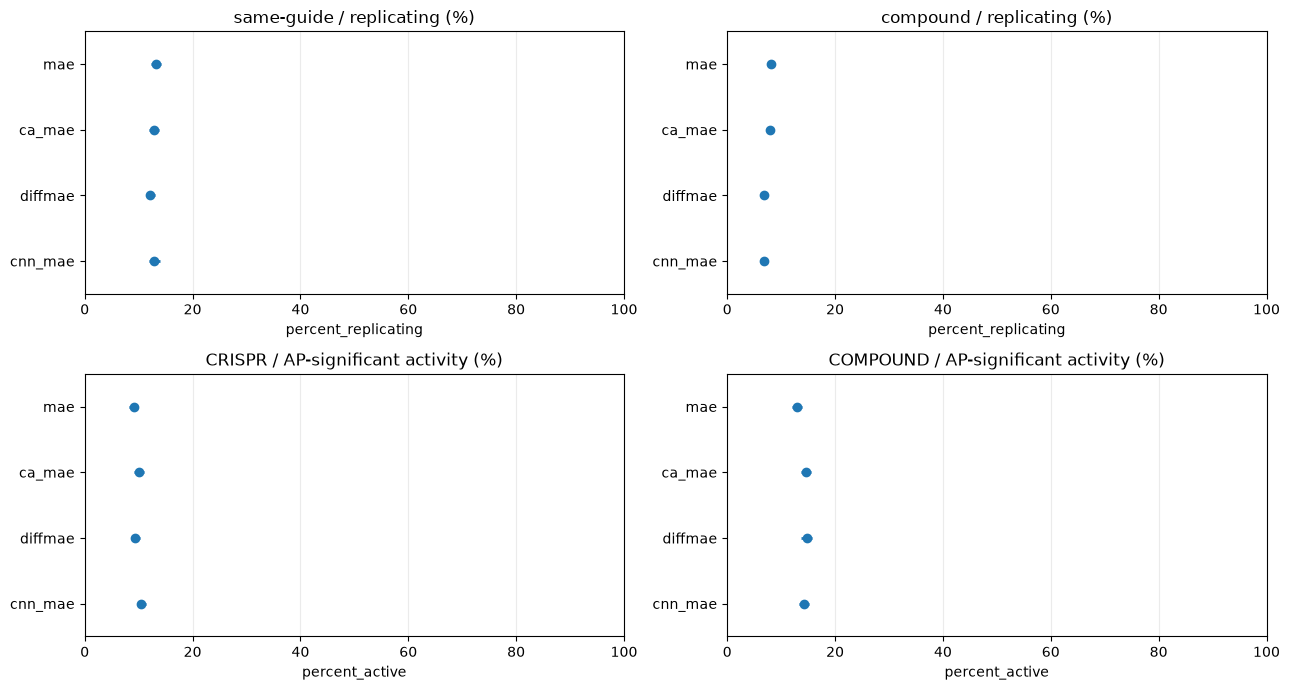

,model,type,n_groups,n_tests,percent_active,percent_energy_active,energy_distance
0,mae,CRISPR,4400,4400,9.090909,10.977273,0.390386
1,ca_mae,CRISPR,4400,4400,10.022727,11.545455,0.400321
2,diffmae,CRISPR,4400,4400,9.363636,11.318182,0.160060
3,cnn_mae,CRISPR,4400,4400,10.454545,12.840909,0.107546
4,mae,COMPOUND,4857,4857,12.909203,44.451307,0.438437
5,ca_mae,COMPOUND,4857,4857,14.700432,50.154416,0.484132
6,diffmae,COMPOUND,4857,4857,14.721021,65.143092,0.276842
7,cnn_mae,COMPOUND,4857,4857,14.185711,58.760552,0.134980


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), squeeze=False)
for ax, task in zip(axes.flat, ('same-guide', 'compound', 'cross-guide')):
    for name in models:
        if (name, task) not in results:
            continue
        stats = results[name, task]['summary']
        ks = protocol['ks']
        ys = [np.nan if stats.get(f'recall@{k}') is None else stats[f'recall@{k}'] for k in ks]
        ax.plot(ks, ys, 'o-', label=name)
    ax.set(title=task, xlabel='K', ylabel='Recall@K', ylim=(0, 1))
    ax.set_xticks(protocol['ks'])
    ax.grid(alpha=0.2)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, max(7, len(models) * 0.8)), squeeze=False)
for ax, task in zip(axes[0], ('same-guide', 'compound')):
    records = [(name, results[name, task]['summary']) for name in models if (name, task) in results]
    points(ax, records, 'percent_replicating', bounds=(0, 100))
    ax.set_title(task + ' / replicating (%)')
activity_rows = []
for ax, kind in zip(axes[1], ('CRISPR', 'COMPOUND')):
    records = []
    for name in models:
        stats = results.get((name, 'activity'), {}).get('summary', {}).get('by_kind', {}).get(kind)
        if stats:
            records.append((name, stats))
            activity_rows.append({'model': name, 'type': kind, **{key: stats.get(key) for key in
                                 ('n_groups', 'n_tests', 'percent_active', 'percent_energy_active', 'energy_distance')}})
    points(ax, records, 'percent_active', bounds=(0, 100))
    ax.set_title(kind + ' / AP-significant activity (%)')
plt.tight_layout()
plt.show()
display(pd.DataFrame(activity_rows))

## 4. 各扰动组表现分布

ECDF 使用已保存的分组 AP/MRR，每个扰动组一票；不把重复 well 当成独立生物学重复。
曲线越偏右表示较多组得分较高，但应结合覆盖率与主指标 CI。

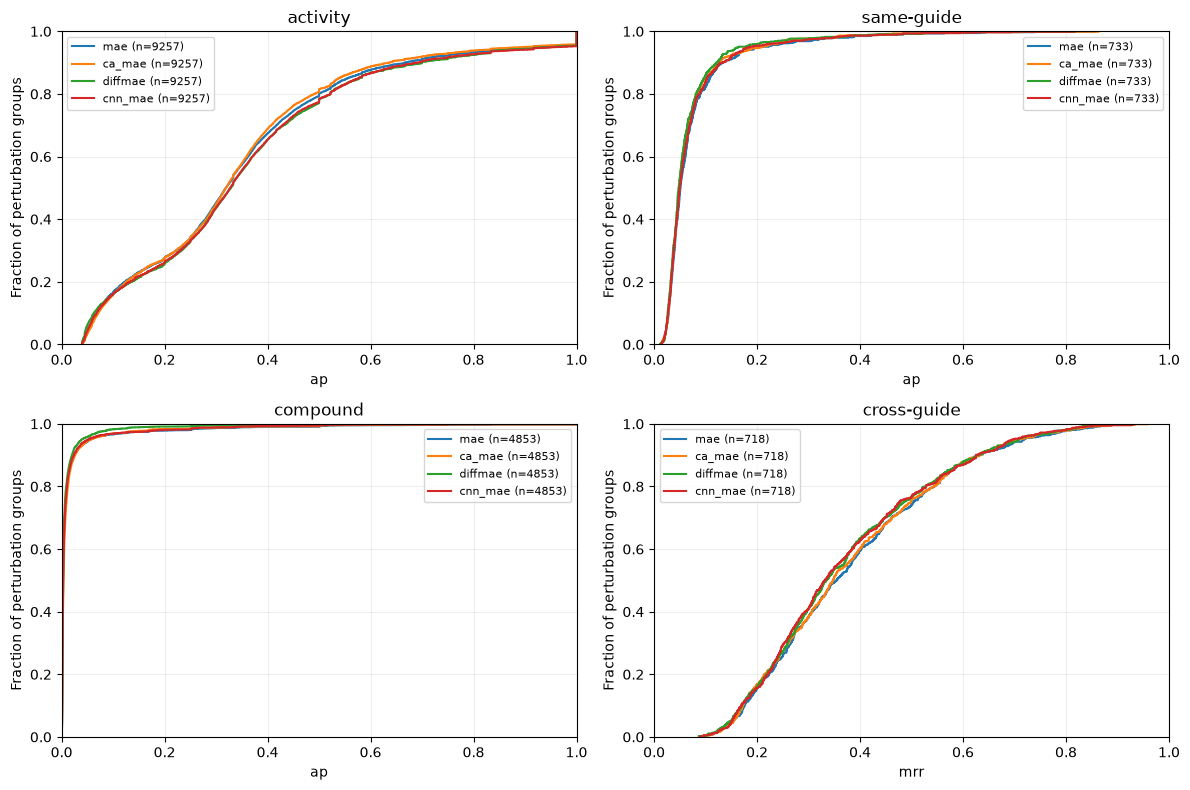

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for ax, task in zip(axes.flat, TASKS):
    field = 'mrr' if task == 'cross-guide' else 'ap'
    for name in models:
        path = RESULT_DIR / name / task / 'groups.csv'
        if not path.is_file():
            continue
        frame = pd.read_csv(path)
        if field not in frame:
            continue
        values = np.sort(pd.to_numeric(frame[field], errors='coerce').dropna().to_numpy())
        if len(values):
            ax.step(values, np.arange(1, len(values) + 1) / len(values), where='post', label=f'{name} (n={len(values)})')
    ax.set(title=task, xlabel=field, ylabel='Fraction of perturbation groups', xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.2)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. 配对差值：相对于一个参考模型

只读 `paired_differences.csv` 的配对扰动 bootstrap CI，不能用两个独立 CI 的端点相减。
正值代表 other − baseline > 0。不同任务分面展示；单模型运行时无配对结果。

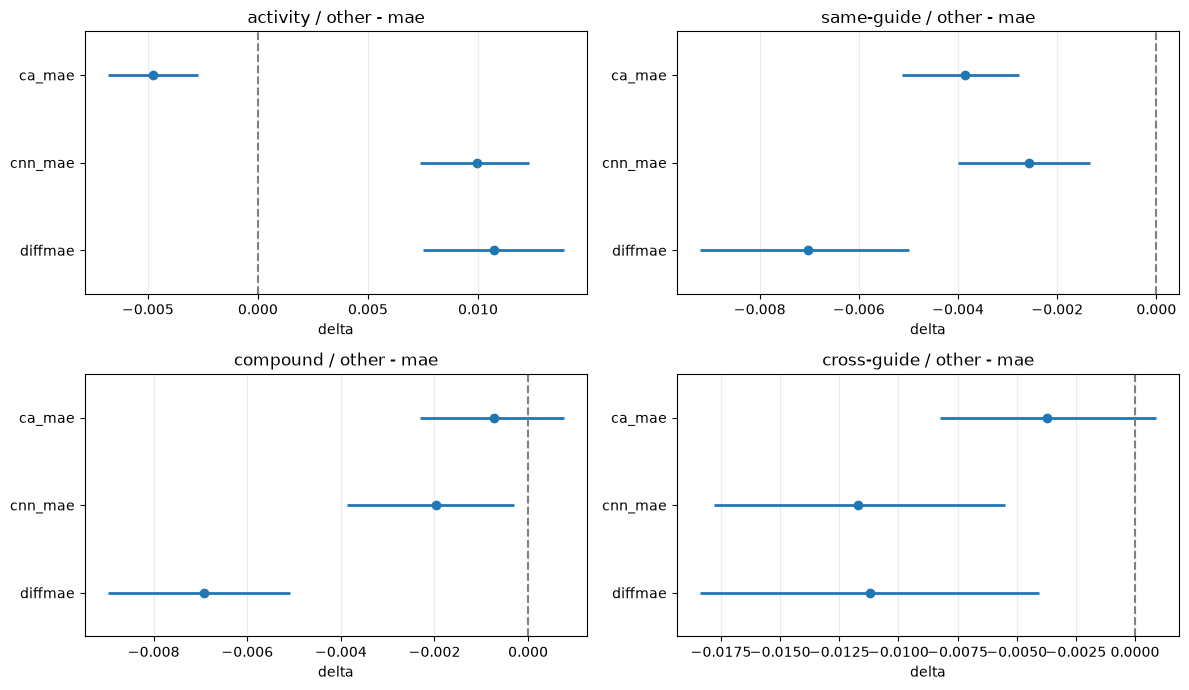

In [8]:
BASELINE_MODEL = models[0]  # 可改为 'OpenPhenom' 或某个自训练模型名。
paired = pd.read_csv(RESULT_DIR / 'paired_differences.csv')
fig, axes = plt.subplots(2, 2, figsize=(12, max(7, len(models) * 0.7)), squeeze=False)
for ax, task in zip(axes.flat, TASKS):
    records = []
    for row in paired.loc[paired.task.eq(task)].itertuples():
        if BASELINE_MODEL not in (row.model_a, row.model_b):
            continue
        sign = 1 if row.model_a == BASELINE_MODEL else -1
        other = row.model_b if sign == 1 else row.model_a
        lo, hi = row.ci95_lower, row.ci95_upper
        interval = [lo, hi] if sign == 1 else [-hi, -lo]
        records.append((other, {'delta': sign * row.delta_b_minus_a, 'ci95': {'delta': interval}}))
    points(ax, records, 'delta', bounds=None)
    ax.axvline(0, linestyle='--', color='gray')
    ax.set_title(task + ' / other - ' + BASELINE_MODEL)
plt.tight_layout()
plt.show()

## 6. 选择模型、任务和扰动组查看诊断

查看每组 AP/MRR、query 排除原因、activity 匹配 block，以及 PR 的观测相似度与 null 95% 阈值。
可填写 `GROUP_LABEL` 筛选单组。表型活性不是独立的处理预测准确率；无有效对照或 null 的结果不记为阴性。

In [9]:
MODEL = models[0]
TASK = next(task for task in TASKS if (MODEL, task) in results)
GROUP_LABEL = ''
DISPLAY_ROWS = 20
result = results[MODEL, TASK]
display(pd.Series(result['summary'], name='value').to_frame())
tables = {}
for filename in ('groups.csv', 'queries.csv', 'blocks.csv', 'replicates.csv'):
    path = RESULT_DIR / MODEL / TASK / filename
    if not path.is_file():
        continue
    frame = pd.read_csv(path)
    if GROUP_LABEL and 'perturbation_label' in frame:
        frame = frame.loc[frame.perturbation_label.eq(GROUP_LABEL)]
    tables[filename] = frame
    field = 'mrr' if TASK == 'cross-guide' else 'ap'
    if filename == 'groups.csv' and field in frame:
        frame = frame.sort_values(field)
    print(filename, '| rows:', len(frame))
    display(frame.head(DISPLAY_ROWS))
replicates = tables.get('replicates.csv', pd.DataFrame())
if {'median_similarity', 'null_q95'} <= set(replicates):
    valid = replicates[['median_similarity', 'null_q95']].dropna()
    if not valid.empty:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.scatter(valid.null_q95, valid.median_similarity, s=15, alpha=0.6)
        low, high = valid.to_numpy().min(), valid.to_numpy().max()
        ax.plot([low, high], [low, high], '--', color='gray')
        ax.set(xlabel='Matched null 95% threshold', ylabel='Observed replicate similarity', title=MODEL + ' / ' + TASK)
        plt.tight_layout()
        plt.show()

,value
n_groups,9257
ci95,"{'map': [0.34539619111008246, 0.35479516870987..."
map,0.350061
energy_distance,0.415598
percent_active,11.094307
percent_energy_active,28.540564
n_queries,14696
n_evaluable_queries,14621
coverage,0.994897
n_groups_available,9265


groups.csv | rows: 9257


,active,active_fraction,ap,energy_active,energy_active_fraction,energy_distance,energy_p_value,energy_q_value,map,n_blocks,n_blocks_requested,n_query_wells,p_value,perturbation_label,perturbation_type,q_value,reason
1753,False,0.0,0.039744,True,1.0,0.445242,0.001998,0.008838,0.039744,1,1,1,1.000000,compound:Glycopyrrolate|dose:0.025,COMPOUND,1.0,NaN
93,False,0.0,0.039744,True,1.0,0.867299,0.000999,0.005756,0.039744,1,1,1,1.000000,compound:A 939572|dose:1E+1,COMPOUND,1.0,NaN
1701,False,0.0,0.039744,True,1.0,0.800010,0.001998,0.008838,0.039744,1,1,1,1.000000,compound:GF109203X|dose:1E+1,COMPOUND,1.0,NaN
2515,False,0.0,0.039744,True,1.0,0.543730,0.001998,0.008838,0.039744,1,1,1,1.000000,compound:Nortriptyline|dose:1,COMPOUND,1.0,NaN
157,False,0.0,0.039744,True,1.0,0.796676,0.000999,0.005756,0.039744,1,1,1,1.000000,compound:AZD2858|dose:1E+1,COMPOUND,1.0,NaN
1030,False,0.0,0.039744,True,1.0,0.688945,0.000999,0.005756,0.039744,1,1,1,1.000000,compound:Cyclizine|dose:2.5,COMPOUND,1.0,NaN
4039,False,0.0,0.039744,True,1.0,0.597988,0.002997,0.011608,0.039744,1,1,1,1.000000,compound:carprofen|dose:1,COMPOUND,1.0,NaN
2304,False,0.0,0.039744,True,1.0,0.507751,0.000999,0.005756,0.039744,1,1,1,1.000000,compound:Methenamine|dose:0.025,COMPOUND,1.0,NaN
1355,False,0.0,0.039886,True,1.0,0.570619,0.000999,0.005756,0.039886,1,1,1,1.000000,compound:Efonidipine|dose:0.25,COMPOUND,1.0,NaN
4798,False,0.0,0.039886,True,1.0,0.637542,0.002997,0.011608,0.039886,1,1,1,1.000000,compound:tavaborole|dose:1,COMPOUND,1.0,NaN


queries.csv | rows: 14696


,ap,experiment_name,n_candidates,n_positives,perturbation_label,perturbation_type,random_ap,reason,well_id
0,0.201923,compound-001,34.0,2.0,compound:GSK256066|dose:0.25,COMPOUND,0.147756,NaN,compound-001_22_AA02
1,0.120370,compound-001,34.0,2.0,compound:Acepromazine|dose:0.1,COMPOUND,0.147756,NaN,compound-001_22_AA22
2,0.056268,compound-001,34.0,2.0,compound:Loratadine|dose:1E+1,COMPOUND,0.147756,NaN,compound-001_22_AA32
3,0.138095,compound-001,34.0,2.0,compound:IMD 0354|dose:1E+1,COMPOUND,0.147756,NaN,compound-001_22_AA35
4,0.200000,compound-001,34.0,2.0,compound:Sucrose|dose:1E+1,COMPOUND,0.147756,NaN,compound-001_22_AA39
5,0.044563,compound-001,34.0,2.0,compound:Nitromide|dose:1,COMPOUND,0.147756,NaN,compound-001_22_AA45
6,0.118056,compound-001,34.0,2.0,compound:Oxymetazoline|dose:2.5,COMPOUND,0.147756,NaN,compound-001_22_AB05
7,0.180556,compound-001,34.0,2.0,compound:6-Thioguanine|dose:1,COMPOUND,0.147756,NaN,compound-001_22_AB06
8,0.051190,compound-001,34.0,2.0,compound:Butanedioic acid|dose:0.1,COMPOUND,0.147756,NaN,compound-001_22_AB07
9,0.162338,compound-001,34.0,2.0,compound:Papaverine|dose:1,COMPOUND,0.147756,NaN,compound-001_22_AB09


blocks.csv | rows: 13377


,ap,energy_distance,energy_p_value,experiment_name,match_context,n_queries,p_value,perturbation_label,perturbation_type,plates,reason
0,0.075463,0.425293,0.005994,compound-004,{'cell_type': 'HUVEC'},1.0,0.612388,compound:1-Octanol|dose:0.0025,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
1,0.120152,0.437608,0.000999,compound-004,{'cell_type': 'HUVEC'},1.0,0.330669,compound:1-Octanol|dose:0.01,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
2,0.519298,0.387290,0.013986,compound-004,{'cell_type': 'HUVEC'},1.0,0.004995,compound:1-Octanol|dose:0.025,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
3,0.139394,0.447116,0.007992,compound-004,{'cell_type': 'HUVEC'},1.0,0.243756,compound:1-Octanol|dose:0.1,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
4,0.265173,0.332438,0.100899,compound-004,{'cell_type': 'HUVEC'},1.0,0.076923,compound:1-Octanol|dose:0.25,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
5,0.101832,0.384354,0.020979,compound-004,{'cell_type': 'HUVEC'},1.0,0.384615,compound:1-Octanol|dose:1,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
6,0.052235,0.310896,0.193806,compound-004,{'cell_type': 'HUVEC'},1.0,0.930070,compound:1-Octanol|dose:1E+1,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
7,0.059216,0.384331,0.001998,compound-004,{'cell_type': 'HUVEC'},1.0,0.828172,compound:1-Octanol|dose:2.5,COMPOUND,"[{'batch_id': 'compound-004/1', 'role': 'galle...",NaN
8,0.054985,0.283736,0.197802,compound-001,{'cell_type': 'HUVEC'},1.0,0.891109,compound:17-AAG|dose:0.0025,COMPOUND,"[{'batch_id': 'compound-001/13', 'role': 'gall...",NaN
9,0.534483,0.355146,0.056943,compound-001,{'cell_type': 'HUVEC'},1.0,0.044955,compound:17-AAG|dose:0.01,COMPOUND,"[{'batch_id': 'compound-001/13', 'role': 'gall...",NaN
